## Representación en grafos: Predicción de enlaces

- ¿Los embeddings anticipan **qué proveedores empezarán a competir juntos**?

- Protocolo **temporal sin fuga**: lo que se aprende de un año se evalúa en el siguiente

- **Local** (scikit-learn): 200k pares × 32 features

### Protocolo

| Paso | Datos | Qué se ve |
|---|---|---|
| Embedding | Grafo de co-participación de **2023** | Solo 2023 |
| Entrenamiento del clasificador | Pares **nuevos en 2024** vs pares sin arista | Features del embedding 2023 |
| Evaluación | Pares **nuevos en 2025** que no estaban en 2023 ni en 2024 | Mismo embedding y mismo clasificador |

- **Nodos:** solo proveedores activos en 2023 (con al menos una arista ese año)

- **Evaluación por pares:** el modelo da un puntaje a cada par

- El AUC es el % de comparaciones (positivo vs negativo) en que el positivo tiene más puntaje (0.5 = azar)

### Constantes

- `MAX_POS` = 50,000: positivos que se muestrean por año

- `FRAC_DIFICIL` = 0.5: fracción de negativos a 2 saltos

- `N_CAND` = 300,000: pares candidatos a 2 saltos que se puntúan

- `TOP_PARES` = 30: pares con mayor probabilidad que se listan

- `CONFIGS_LP`: embeddings que se comparan

- `N_JOBS` = 4: núcleos del random forest

In [1]:
CONFIGS_LP = ["p1_q1", "p0.25_q4", "p4_q0.25", "svd"]
N_JOBS = 4
MAX_POS = 50000
FRAC_DIFICIL = 0.5
N_CAND = 300000
TOP_PARES = 30

### Utilidades

- Un solo hilo para BLAS/OpenMP **antes** de importar numpy: 

- El contenedor ve 24 CPUs y, sin límite, los hilos de OpenBLAS quedan en espera activa entre operaciones chicas

In [2]:
import os
for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[v_] = "1"

In [3]:
NOTEBOOK = "d_enlaces"
%run ../funciones.ipynb
%run funciones.ipynb
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, precision_recall_curve

Note: you may need to restart the kernel to use updated packages.


In [4]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

In [5]:
config = leer_config()
nodos = pd.read_parquet(datos_dir / "nodos.parquet")
aristas_anio = pd.read_parquet(datos_dir / "aristas_anio.parquet")
n = len(nodos)
nodos["tipologia"] = tipologia_proveedor(nodos.clave)
rng = np.random.default_rng(SEED)

---
### **1. Conjuntos de entrenamiento y test**

In [6]:
A23 = grafo_anios(aristas_anio, [2023], n)
A24 = grafo_anios(aristas_anio, [2024], n)
A25 = grafo_anios(aristas_anio, [2025], n)
act = np.flatnonzero(np.diff(A23.indptr) > 0)
llaves_anio = lambda M: _llave(*sp.triu(M, 1).nonzero(), n)

pos_tr = pares_nuevos(aristas_anio, 2024, A23, act)
pos_te = pares_nuevos(aristas_anio, 2025, A23 + A24, act)
pos_tr = pos_tr[rng.choice(len(pos_tr), min(MAX_POS, len(pos_tr)), replace=False)]
pos_te = pos_te[rng.choice(len(pos_te), min(MAX_POS, len(pos_te)), replace=False)]
neg_tr = negativos(A23, llaves_anio(A24), act, len(pos_tr), FRAC_DIFICIL, rng)
neg_te = negativos(A23, np.r_[llaves_anio(A24), llaves_anio(A25)], act, len(pos_te), FRAC_DIFICIL, rng)

def armar(pos, neg):
    return pd.DataFrame({"i": np.r_[pos[:, 0], neg[:, 0]], "j": np.r_[pos[:, 1], neg[:, 1]],
                         "y": np.r_[np.ones(len(pos)), np.zeros(len(neg))].astype(int),
                         "tipo": ["positivo"] * len(pos) + np.where(neg[:, 2] == 1, "neg 2 saltos", "neg al azar").tolist()})
tr, te = armar(pos_tr, neg_tr), armar(pos_te, neg_te)
k_te_pos = set(_llave(te.i[te.y == 1], te.j[te.y == 1], n))
fuga = k_te_pos & set(_llave(tr.i[tr.y == 1], tr.j[tr.y == 1], n))
cambia = k_te_pos & set(_llave(tr.i[tr.y == 0], tr.j[tr.y == 0], n))
conjuntos = pd.DataFrame([
    ("nodos activos en 2023", len(act)), ("aristas 2023", A23.nnz // 2),
    ("train: positivos (nuevos 2024)", (tr.y == 1).sum()), ("train: negativos", (tr.y == 0).sum()),
    ("test: positivos (nuevos 2025)", (te.y == 1).sum()), ("test: negativos", (te.y == 0).sum()),
    ("positivos de test que son positivos de train (fuga)", len(fuga)),
    ("negativos de train (2024) que pasan a positivos en test (2025)", len(cambia)),
    ("test: positivos que tocan una arista 2023 (A23 > 0)", int((np.asarray(A23[te.i[te.y == 1], te.j[te.y == 1]]).ravel() > 0).sum()))],
    columns=["medida", "valor"])
conjuntos

,medida,valor
0,nodos activos en 2023,30632
1,aristas 2023,482854
2,train: positivos (nuevos 2024),50000
3,train: negativos,50000
4,test: positivos (nuevos 2025),50000
5,test: negativos,50000
6,positivos de test que son positivos de train (fuga),0
7,negativos de train (2024) que pasan a positivos en test (2025),153
8,test: positivos que tocan una arista 2023 (A23 > 0),0


In [7]:
log("conjuntos listos")

[09:18:50] conjuntos listos


- **Grafo 2023:** 30,632 proveedores activos y 482,854 aristas

- **50k positivos y 50k negativos** en train y en test

- **Sin fuga:** ningún positivo de test es positivo de train, y ninguno tocaba una arista de 2023

- **134 pares** fueron negativos en train (no compitieron en 2024) y compiten en 2025

---
### **2. Embeddings del grafo 2023**

- Las configuraciones de `CONFIGS_LP`, con la dimensión y los paseos; solo sobre el grafo 2023

- Cada embedding se guarda al terminar; si ya existe con la misma dimensión, se lee en vez de recalcular

In [8]:
DIM = config["dim"]
kw = dict(n_paseos=config["n_paseos"], largo=config["largo"], ventana=config["ventana"], epocas=config["epocas"])
emb23, t_emb = {}, []
for c in CONFIGS_LP:
    ruta = datos_dir / f"emb23_{c}.npy"
    t0 = time.time()
    if ruta.exists() and np.load(ruta).shape == (n, DIM):
        E = np.load(ruta)
    elif c == "svd":
        E = np.zeros((n, DIM), dtype=np.float32)
        E[act] = embedding_svd(A23[act][:, act], DIM)
    else:
        p, q = (float(x[1:]) for x in c.split("_"))
        E, _, _ = node2vec_activos(A23, p, q, DIM, **kw)
    np.save(ruta, E)
    emb23[c] = E
    t_emb.append({"config": c, "tiempo_s": round(time.time() - t0, 1)})
    log(f"embedding 2023 {c}: {time.time() - t0:.0f} s")
t_emb = pd.DataFrame(t_emb)
t_emb

[09:18:50] embedding 2023 p1_q1: 0 s


[09:18:50] embedding 2023 p0.25_q4: 0 s


[09:18:50] embedding 2023 p4_q0.25: 0 s


[09:18:50] embedding 2023 svd: 0 s


,config,tiempo_s
0,p1_q1,0.0
1,p0.25_q4,0.0
2,p4_q0.25,0.0
3,svd,0.0


---
### **3. Clasificadores y líneas base**

- **Features:** operador de par (Hadamard, L1, L2) sobre los dos embeddings

- **Regresión logística** (estandarizada) para todas las configuraciones y operadores

- **Random forest** (`N_JOBS` núcleos) para las 3 mejores combinaciones de la logística

In [9]:
def evaluar(modelo, c, op):
    X_tr, X_te = features_par(emb23[c], tr.i, tr.j, op), features_par(emb23[c], te.i, te.j, op)
    t0 = time.time()
    s = modelo.fit(X_tr, tr.y).predict_proba(X_te)[:, 1]
    return s, time.time() - t0

res, puntajes = [], {}
for c in emb23:
    for op in OPERADORES:
        s, t = evaluar(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), c, op)
        puntajes[("logística", c, op)] = s
        res.append({"modelo": "logística", "config": c, "operador": op, **metricas_ranking(te.y, s), "tiempo_s": t})
    log(f"logística {c}: 3 operadores")
res = pd.DataFrame(res)
for _, r in res.nlargest(3, "pr_auc").iterrows():
    s, t = evaluar(RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=5, n_jobs=N_JOBS, random_state=SEED),
                   r.config, r.operador)
    log(f"random forest {r.config} {r.operador}")
    puntajes[("random forest", r.config, r.operador)] = s
    res.loc[len(res)] = {"modelo": "random forest", "config": r.config, "operador": r.operador, **metricas_ranking(te.y, s), "tiempo_s": t}
base = {f"coseno {c}": (normalizar(emb23[c])[te.i] * normalizar(emb23[c])[te.j]).sum(1) for c in ("p1_q1", "svd")}
base.update(heuristicas(A23, te.i.to_numpy(), te.j.to_numpy()))
for b_, s in base.items():
    puntajes[("base", b_, "—")] = s
    res.loc[len(res)] = {"modelo": "base", "config": b_, "operador": "—", **metricas_ranking(te.y, s), "tiempo_s": 0.0}
res = res.round(4).sort_values("pr_auc", ascending=False, ignore_index=True)
res.head(15)

[09:18:52] logística p1_q1: 3 operadores


[09:18:53] logística p0.25_q4: 3 operadores


[09:18:54] logística p4_q0.25: 3 operadores


[09:18:56] logística svd: 3 operadores


[09:19:39] random forest p0.25_q4 hadamard


[09:20:22] random forest p1_q1 hadamard


[09:21:06] random forest p4_q0.25 hadamard


,modelo,config,operador,roc_auc,pr_auc,tiempo_s
0,random forest,p0.25_q4,hadamard,0.7433,0.7204,42.8984
1,random forest,p1_q1,hadamard,0.7366,0.7109,43.1607
2,random forest,p4_q0.25,hadamard,0.7267,0.7006,44.0189
3,logística,p0.25_q4,hadamard,0.7161,0.6899,0.3311
4,logística,p1_q1,hadamard,0.7043,0.6694,0.3603
5,logística,p4_q0.25,hadamard,0.6892,0.6487,0.3660
6,base,vecinos_comunes,—,0.6448,0.6446,0.0000
7,base,adamic_adar,—,0.6323,0.6380,0.0000
8,logística,svd,hadamard,0.6544,0.6235,0.9236
9,base,coseno svd,—,0.6526,0.6000,0.0000


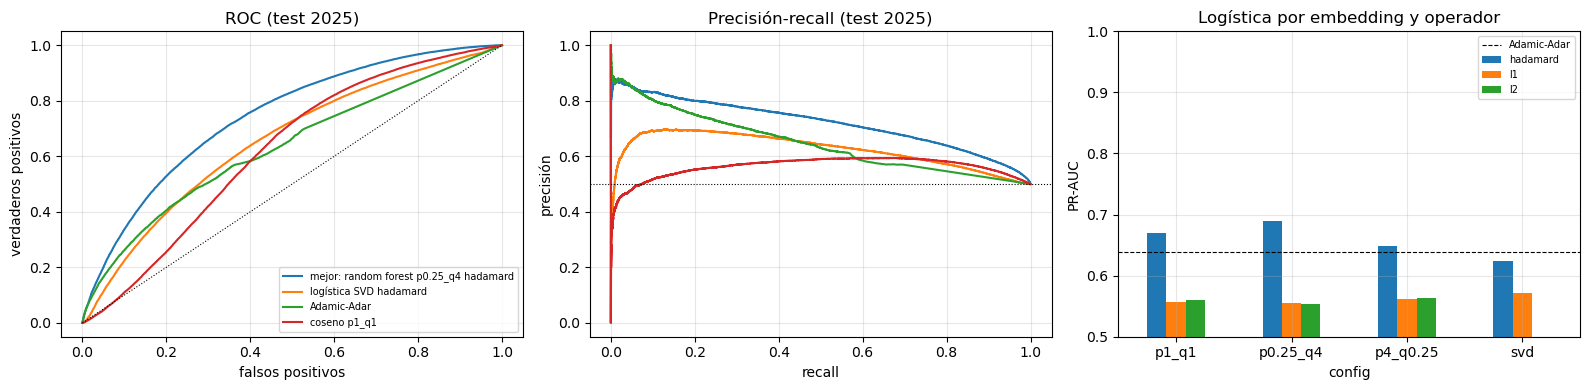

In [10]:
mejor = res.iloc[0]
s_mejor = puntajes[(mejor.modelo, mejor.config, mejor.operador)]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for (mod, c, op), lbl in [((mejor.modelo, mejor.config, mejor.operador), f"mejor: {mejor.modelo} {mejor.config} {mejor.operador}"),
                          (("logística", "svd", "hadamard"), "logística SVD hadamard"), (("base", "adamic_adar", "—"), "Adamic-Adar"),
                          (("base", "coseno p1_q1", "—"), "coseno p1_q1")]:
    s = puntajes[(mod, c, op)]
    fpr, tpr, _ = roc_curve(te.y, s); pr, rc, _ = precision_recall_curve(te.y, s)
    ax[0].plot(fpr, tpr, label=lbl); ax[1].plot(rc, pr, label=lbl)
ax[0].plot([0, 1], [0, 1], "k:", lw=.8)
ax[0].set(xlabel="falsos positivos", ylabel="verdaderos positivos", title="ROC (test 2025)"); ax[0].legend(fontsize=7)
ax[1].axhline(te.y.mean(), color="k", ls=":", lw=.8)
ax[1].set(xlabel="recall", ylabel="precisión", title="Precisión-recall (test 2025)")
M = res[res.modelo == "logística"].pivot(index="config", columns="operador", values="pr_auc").loc[CONFIGS_LP]
M.plot.bar(ax=ax[2], rot=0)
ax[2].axhline(res.loc[res.config == "adamic_adar", "pr_auc"].iloc[0], color="k", ls="--", lw=.8, label="Adamic-Adar")
ax[2].set(ylim=(.5, 1), ylabel="PR-AUC", title="Logística por embedding y operador"); ax[2].legend(fontsize=7)
mostrar_fig("enlaces_curvas")

- **Mejor modelo: random forest sobre Hadamard** de Node2Vec, con **ROC-AUC 0.74 y PR-AUC 0.72** (azar = 0.5)

- **Supera a las heurísticas clásicas:** vecinos comunes (PR-AUC 0.643) y Adamic-Adar (0.637)

- **Hadamard es el único operador que funciona** (0.65-0.69 vs 0.55-0.56 con L1/L2)

- Producto elemento a elemento mide en qué dimensiones **coinciden** los dos proveedores

- **Node2Vec > SVD** (0.65-0.69 vs 0.62 con logística): los paseos generalizan mejor a pares que todavía no comparten

- **p y q casi no importan:** BFS (0.25, 4) 0.721, referencia (1, 1) 0.710 y DFS (4, 0.25) 0.699 con random forest

- **El coseno solo** (0.56) queda bajo las heurísticas: falta un clasificador que aprenda **qué dimensiones** importan

#### a. Negativos fáciles y difíciles

AUC del mejor modelo separando los positivos de cada tipo de negativo

In [11]:
por_tipo = pd.DataFrame([{"negativos": t_, "roc_auc": roc_auc_score(te.y[m_], s_mejor[m_]),
                          "roc_auc_adamic_adar": roc_auc_score(te.y[m_], puntajes[("base", "adamic_adar", "—")][m_])}
                         for t_ in ("neg al azar", "neg 2 saltos") for m_ in [(te.tipo == "positivo") | (te.tipo == t_)]]).round(4)
por_tipo

,negativos,roc_auc,roc_auc_adamic_adar
0,neg al azar,0.8835,0.8331
1,neg 2 saltos,0.6032,0.4315


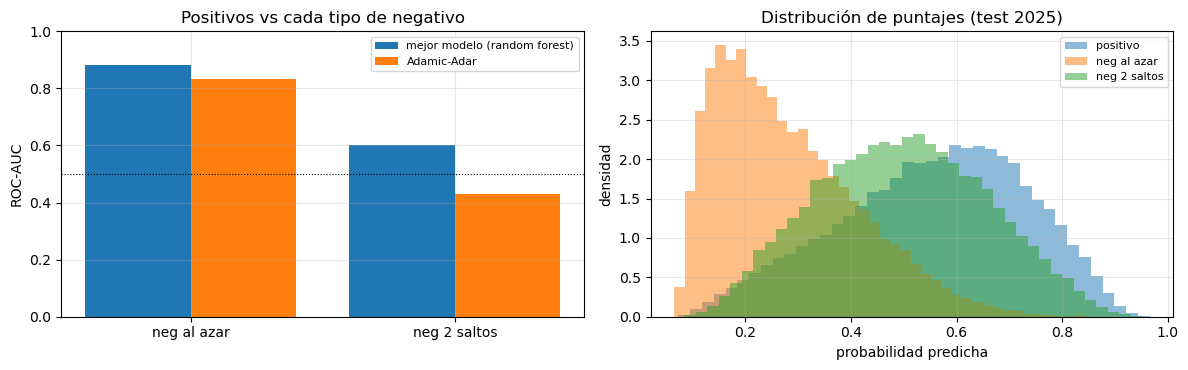

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x_ = np.arange(len(por_tipo))
ax[0].bar(x_ - .2, por_tipo.roc_auc, .4, label=f"mejor modelo ({mejor.modelo})")
ax[0].bar(x_ + .2, por_tipo.roc_auc_adamic_adar, .4, label="Adamic-Adar")
ax[0].axhline(.5, color="k", ls=":", lw=.8)
ax[0].set(xticks=x_, xticklabels=por_tipo.negativos, ylim=(0, 1), ylabel="ROC-AUC", title="Positivos vs cada tipo de negativo"); ax[0].legend(fontsize=8)
for t_ in ("positivo", "neg al azar", "neg 2 saltos"):
    ax[1].hist(s_mejor[(te.tipo == t_).to_numpy()], bins=40, alpha=.5, density=True, label=t_)
ax[1].set(xlabel="probabilidad predicha", ylabel="densidad", title="Distribución de puntajes (test 2025)"); ax[1].legend(fontsize=8)
mostrar_fig("negativos")

- **Negativos al azar:** el modelo los separa bien (ROC-AUC 0.88; Adamic-Adar 0.83)

- **Negativos a 2 saltos** (comparten un competidor y no compiten entre sí)

- Las heurísticas puntúan alto a todo par con vecinos comunes

- Ahí está el valor agregado del embedding: el caso difícil y realista

- Los positivos se centran en 0.6, los negativos al azar en 0.2 y los de 2 saltos en 0.5

---
### **4. Pares predichos que aún no compiten juntos**

- Candidatos: `N_CAND` pares **a 2 saltos** en el grafo 2023, sin arista en 2023 ni en 2024

- Se puntúan con el mejor modelo y se listan los de mayor probabilidad

- **Verificación:** si el par apareció como arista en **2025**

In [13]:
cand = negativos(A23, llaves_anio(A24), act, N_CAND, 1.0, np.random.default_rng(SEED + 1))
ci, cj = cand[:, 0], cand[:, 1]
if mejor.modelo == "base":
    s_c = base[mejor.config] if mejor.config in base else heuristicas(A23, ci, cj)[mejor.config]
else:
    mod_c = (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)) if mejor.modelo == "logística" else
             RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=5, n_jobs=N_JOBS, random_state=SEED))
    mod_c.fit(features_par(emb23[mejor.config], tr.i, tr.j, mejor.operador), tr.y)
    s_c = mod_c.predict_proba(features_par(emb23[mejor.config], ci, cj, mejor.operador))[:, 1]
log(f"{len(cand):,} candidatos puntuados")
en_2025 = np.asarray(A25[ci, cj]).ravel() > 0
orden = np.argsort(-s_c)
precision_top = pd.DataFrame([{"top": k, "% aparece en 2025": 100 * en_2025[orden[:k]].mean()} for k in (30, 100, 1000, 10000)] +
                             [{"top": len(cand), "% aparece en 2025": 100 * en_2025.mean()}]).round(2)
precision_top

[09:21:55] 300,000 candidatos puntuados


,top,% aparece en 2025
0,30,13.33
1,100,11.00
2,1000,7.30
3,10000,5.22
4,300000,1.32


In [14]:
cols = ["nombre", "region", "familia", "tipologia", "n_procesos", "n_ganados"]
a_, b_ = nodos.iloc[ci[orden[:TOP_PARES]]][cols].reset_index(drop=True), nodos.iloc[cj[orden[:TOP_PARES]]][cols].reset_index(drop=True)
top_pares = pd.concat([a_.add_suffix("_a"), b_.add_suffix("_b")], axis=1)
top_pares.insert(0, "probabilidad", s_c[orden[:TOP_PARES]].round(3))
top_pares["aparece_2025"] = en_2025[orden[:TOP_PARES]].astype(int)
top_pares["misma_region"] = (top_pares.region_a == top_pares.region_b).astype(int)
top_pares["misma_familia"] = (top_pares.familia_a == top_pares.familia_b).astype(int)
top_pares[["probabilidad", "nombre_a", "nombre_b", "region_a", "region_b", "familia_a", "familia_b", "aparece_2025"]].head(15)

,probabilidad,nombre_a,nombre_b,region_a,region_b,familia_a,familia_b,aparece_2025
0,0.967,JL BUSINESS AND SERVICE S.A.C.,VP SOLUTIONS PERU S.A.C,LIMA,LIMA,8016,4321,0
1,0.956,PEREDA DISTRIBUIDORES S R L,VITALIS PERU SAC,LIMA,LIMA,5120,5110,0
2,0.955,DROGUERIA INTERNATIONAL FARMA S.A.,REYOUNG PHARMA S.A.C.,LIMA,LIMA,5111,5110,0
3,0.954,CHARQUI BELTRAN MAURICIO VICTORIANO,INKA REAL PERU S.A.C.,LIMA,LIMA,5013,5022,0
4,0.953,LABORATORIOS PORTUGAL S R L,PHARMINTEGRA S.A.C.,LIMA,LIMA,5114,5110,0
5,0.953,ASG FARMA S.A.C.,ROMAT PHARMACEUTICAL S.A.C.,LIMA,LIMA,5110,5114,0
6,0.951,DROGUERIA INVERSIONES JPS SAC,INVERSIONES ELESNA MEDIC S.A.C.,LIMA,LIMA,5110,5119,0
7,0.950,VITALIS PERU SAC,PAK FARMA S.A.C.,LIMA,LIMA,5110,5110,0
8,0.948,IMPROVENG S R LTDA,SEVEN PHARMA SAC,LIMA,LIMA,4213,5110,0
9,0.947,LUNA SANTIVAÑEZ MIGUEL ANGEL,CORPORACION DAKRI E.I.R.L,LIMA,LA LIBERTAD,3011,5022,0


In [15]:
d_ = pd.DataFrame({"s": s_c, "misma_region": nodos.region.to_numpy()[ci] == nodos.region.to_numpy()[cj],
                   "misma_familia": nodos.familia.to_numpy()[ci] == nodos.familia.to_numpy()[cj], "en_2025": en_2025})
d_["decil"] = pd.qcut(d_.s.rank(method="first"), 10, labels=False) + 1
por_decil = d_.groupby("decil")[["misma_region", "misma_familia", "en_2025"]].mean().mul(100).round(1)
por_decil

,misma_region,misma_familia,en_2025
decil,,,
1,37.0,22.9,0.4
2,38.1,27.3,0.6
3,38.3,29.5,0.7
4,37.7,32.0,0.8
5,37.5,33.8,1.0
6,37.6,35.4,0.9
7,38.1,36.7,1.1
8,39.3,38.6,1.6
9,40.3,42.9,2.1


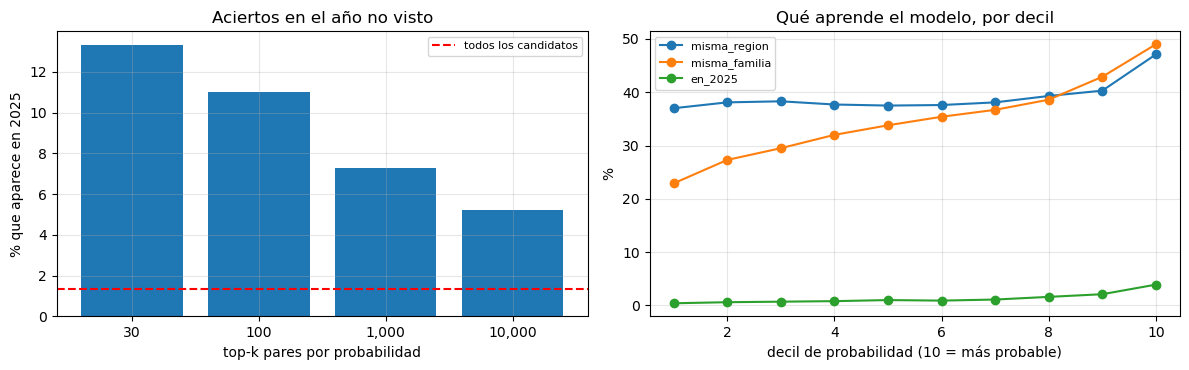

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
p_ = precision_top.iloc[:-1]
ax[0].bar(p_.top.map("{:,}".format), p_["% aparece en 2025"])
ax[0].axhline(precision_top["% aparece en 2025"].iloc[-1], color="red", ls="--", label="todos los candidatos")
ax[0].set(xlabel="top-k pares por probabilidad", ylabel="% que aparece en 2025", title="Aciertos en el año no visto"); ax[0].legend(fontsize=8)
por_decil.plot(ax=ax[1], marker="o")
ax[1].set(xlabel="decil de probabilidad (10 = más probable)", ylabel="%", title="Qué aprende el modelo, por decil"); ax[1].legend(fontsize=8)
mostrar_fig("lift")

- **Lift:** el top 100 aparece en 2025 en un **11%**, frente a **1.3%** de todos los candidatos

- **Por decil:** los pares más probables son más del mismo rubro (23% → 49%) y región (36% → 47%)

- **Top de pares:** distribuidores de **medicamentos e insumos médicos de Lima** → **sustitutos potenciales** (PQ3)

- **Ética:** un enlace predicho es una **afinidad**, no evidencia de acuerdo

---
### **5. Escritura de resultados**

In [17]:
config.update({"lp_mejor": {"modelo": mejor.modelo, "config": mejor.config, "operador": mejor.operador}})
guardar_config(config)
escritos = guardar_tablas({"conjuntos": conjuntos, "tiempos_embedding": t_emb, "resultados": res, "por_tipo_negativo": por_tipo,
                           "precision_top": precision_top, "top_pares": top_pares.fillna("sin dato"),
                           "por_decil": por_decil.reset_index()})

Escrito en 06_Representacion/temp/d_enlaces/: conjuntos, tiempos_embedding, resultados, por_tipo_negativo, precision_top, top_pares, por_decil


#### a. Verificación

In [18]:
assert len(fuga) == 0, "hay positivos de test que también son positivos de train"
verificar_salidas(escritos)

OK: 7 tablas (parquet + json) | 3 figuras: enlaces_curvas, lift, negativos


---
### **6. Cerrar sesión**

In [19]:
spark.stop()